# Binary intrusion detection baseline

This notebook uses the saved training and validation subsets referenced in `02_eda_restart.ipynb` and `03_train_validation_overlap.ipynb`. The test subset is reserved for final evaluation.

## Load the subsets and map labels

Check the common 46-feature schema and validate every original label against the documented vocabulary before mapping benign to 0 and attack to 1.

In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

subset_dir = repo_root / "data/subsets"
paths = {
    "Training": subset_dir / "ciciot2023_train_stratified_100000_seed42.csv",
    "Validation": subset_dir / "ciciot2023_validation_stratified_25000_seed42.csv",
}
frames = {
    split: pd.read_csv(path, low_memory=False, skip_blank_lines=False, dtype={"label": "string"})
    for split, path in paths.items()
}
feature_columns = frames["Training"].columns.drop("label")
if len(feature_columns) != 46:
    raise ValueError(f"Expected 46 feature columns, found {len(feature_columns)}.")

for split, frame in frames.items():
    if not frame.columns.drop("label").equals(feature_columns):
        raise ValueError(f"{split} feature columns differ from the training schema.")
    features = frame[feature_columns]
    if not all(map(is_numeric_dtype, features.dtypes)):
        raise ValueError(f"{split} has nonnumeric feature columns.")
    if not np.isfinite(features.to_numpy()).all():
        raise ValueError(f"{split} has nonfinite features.")

# CSV spellings of the 33 attack types listed by CIC and the dataset paper.
documented_attack_labels = {
    "DDoS-ACK_Fragmentation", "DDoS-HTTP_Flood", "DDoS-ICMP_Flood",
    "DDoS-ICMP_Fragmentation", "DDoS-PSHACK_Flood", "DDoS-RSTFINFlood",
    "DDoS-SYN_Flood", "DDoS-SlowLoris", "DDoS-SynonymousIP_Flood",
    "DDoS-TCP_Flood", "DDoS-UDP_Flood", "DDoS-UDP_Fragmentation",
    "DoS-HTTP_Flood", "DoS-SYN_Flood", "DoS-TCP_Flood", "DoS-UDP_Flood",
    "Recon-HostDiscovery", "Recon-OSScan", "Recon-PingSweep",
    "Recon-PortScan", "VulnerabilityScan",
    "Backdoor_Malware", "BrowserHijacking", "CommandInjection",
    "SqlInjection", "Uploading_Attack", "XSS", "DictionaryBruteForce",
    "DNS_Spoofing", "MITM-ArpSpoofing",
    "Mirai-greeth_flood", "Mirai-greip_flood", "Mirai-udpplain",
}

label_map = {"BenignTraffic": 0, **dict.fromkeys(documented_attack_labels, 1)}
targets = {}
for split, frame in frames.items():
    labels = frame["label"]
    missing = labels.isna() | labels.str.strip().eq("").fillna(False)
    unknown = sorted(labels[~missing & ~labels.isin(label_map)].unique())
    if missing.any() or unknown:
        raise ValueError(f"{split} labels: {missing.sum():,} missing; unknown labels: {unknown!r}.")
    targets[split] = labels.map(label_map).astype(int)

display(pd.DataFrame([
    {"Split": split, "Rows": len(y), "Benign (0)": int(y.eq(0).sum()),
     "Attack (1)": int(y.eq(1).sum())}
    for split, y in targets.items()
]).set_index("Split"))

,Rows,Benign (0),Attack (1)
Split,,,
Training,100000,2359,97641
Validation,25000,585,24415


**Interpretation.** The label check passed for both subsets. The class counts show how strongly attack rows outnumber benign rows.

## Select model inputs

Apply the EDA feature exclusions. Compare `IPv` and `LLC` exactly in training before deciding whether to drop `LLC`. Build the model inputs from the numeric feature columns only.

In [2]:
constant_features = ["ece_flag_number", "cwr_flag_number", "Telnet", "SMTP", "IRC", "DHCP"]
train = frames["Training"]
ipv_llc_equal = bool(train["IPv"].eq(train["LLC"]).all())
dropped = constant_features + ["Srate"]
if ipv_llc_equal:
    dropped.append("LLC")

model_columns = feature_columns.drop(dropped)
model_inputs = {split: frame[model_columns] for split, frame in frames.items()}
print(f"IPv equals LLC in every training row: {ipv_llc_equal}")
print(f"Dropped columns: {', '.join(dropped)}")
print(f"Final model feature count: {len(model_columns)}")

IPv equals LLC in every training row: True
Dropped columns: ece_flag_number, cwr_flag_number, Telnet, SMTP, IRC, DHCP, Srate, LLC
Final model feature count: 38


**Interpretation.** IPv and LLC were identical in every training row, so LLC was dropped. The models use 38 features, including Rate.

## Identify validation overlap

Reuse the exact tuple comparison from `03_train_validation_overlap.ipynb` on all 46 original numeric features, before any model exclusions or scaling. Look up each original validation row once to build the evaluation mask.

In [3]:
patterns_by_split = {}
for split, frame in frames.items():
    patterns = {}
    for row in frame[[*feature_columns, "label"]].itertuples(index=False, name=None):
        feature_key, label = row[:-1], row[-1]
        patterns.setdefault(feature_key, Counter())[label] += 1
    patterns_by_split[split] = patterns

training = patterns_by_split["Training"]
validation = patterns_by_split["Validation"]
shared = training.keys() & validation.keys()

validation_matches = np.fromiter(
    (row in shared for row in frames["Validation"][feature_columns].itertuples(index=False, name=None)),
    dtype=bool,
    count=len(frames["Validation"]),
)
matching_rows = int(validation_matches.sum())
nonmatching_rows = int((~validation_matches).sum())
if (len(shared), matching_rows, nonmatching_rows) != (25, 25, 24_975):
    raise ValueError(
        f"Expected 25 shared patterns, 25 matching and 24,975 nonmatching rows; "
        f"found {len(shared):,}, {matching_rows:,} and {nonmatching_rows:,}."
    )
print(f"Shared patterns: {len(shared):,}")
print(f"Matching validation rows: {matching_rows:,}")
print(f"Nonmatching validation rows: {nonmatching_rows:,}")

Shared patterns: 25
Matching validation rows: 25
Nonmatching validation rows: 24,975


**Interpretation.** The mask reproduced the 25 exact matches. The second evaluation excludes those rows while retaining all 24,975 other rows in their original order.

## Fit both baselines

Fit an always-attack classifier and a pipeline with `StandardScaler` and balanced logistic regression using training only. Generate validation predictions once from attack probabilities at a fixed threshold of 0.5. Check for convergence warnings and report the solver iterations.

In [4]:
import warnings

import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

reference = DummyClassifier(strategy="constant", constant=1)
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", class_weight="balanced", max_iter=2000),
)
X_train, y_train = model_inputs["Training"], targets["Training"]
X_validation = model_inputs["Validation"]

reference.fit(X_train, y_train)
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    logistic.fit(X_train, y_train)

convergence_warnings = [
    str(warning.message) for warning in fit_warnings
    if issubclass(warning.category, ConvergenceWarning)
]
iterations = int(logistic.named_steps["logisticregression"].n_iter_.max())
converged = not convergence_warnings
models = {"Always attack": reference, "Logistic regression": logistic}
threshold = 0.5
predictions = {
    name: (model.predict_proba(X_validation)[:, list(model.classes_).index(1)] >= threshold).astype(int)
    for name, model in models.items()
}
print(f"scikit-learn: {sklearn.__version__}")
print(f"Logistic regression converged: {converged} ({iterations:,} solver iterations)")
for message in convergence_warnings:
    print(message)

scikit-learn: 1.9.1
Logistic regression converged: True (111 solver iterations)


**Interpretation.** The logistic regression solver converged in 111 iterations. Both models use the same 0.5 threshold.

## Score both sets of validation rows

Slice the same saved-in-memory predictions for both evaluations. With attack positive, the confusion matrix is ordered as actual benign and attack down the rows and predicted benign and attack across the columns. The benign false-positive rate divides benign rows predicted as attack by all actual benign rows. Undefined precision for a class with zero predictions is reported as 0.

Rows   TN   FP   FN     TP Benign precision Benign recall Benign F1 Attack precision Attack recall Attack F1 Balanced accuracy  Benign false positives  Actual benign Benign false-positive rate
Model               Validation                                                                                                                                                                                                         
Always attack       All validation    25000    0  585    0  24415          0.0000%       0.0000%   0.0000%         97.6600%     100.0000%  98.8161%          50.0000%                     585            585                  100.0000%
                    Nonmatching only  24975    0  583    0  24392          0.0000%       0.0000%   0.0000%         97.6657%     100.0000%  98.8190%          50.0000%                     583            583                  100.0000%
Logistic regression All validation    25000  581    4  502  23913         53.6473%      99.3162%  69.6643%         99.9833%      97.9439%  98.9531%          98.6301%                       4            585                    0.6838%
                    Nonmatching only  24975  579    4  502  23890         53.5615%      99.3139%  69.5913%         99.9833%      97.9419%  98.9521%          98.6279%                       4            583                    0.6861%

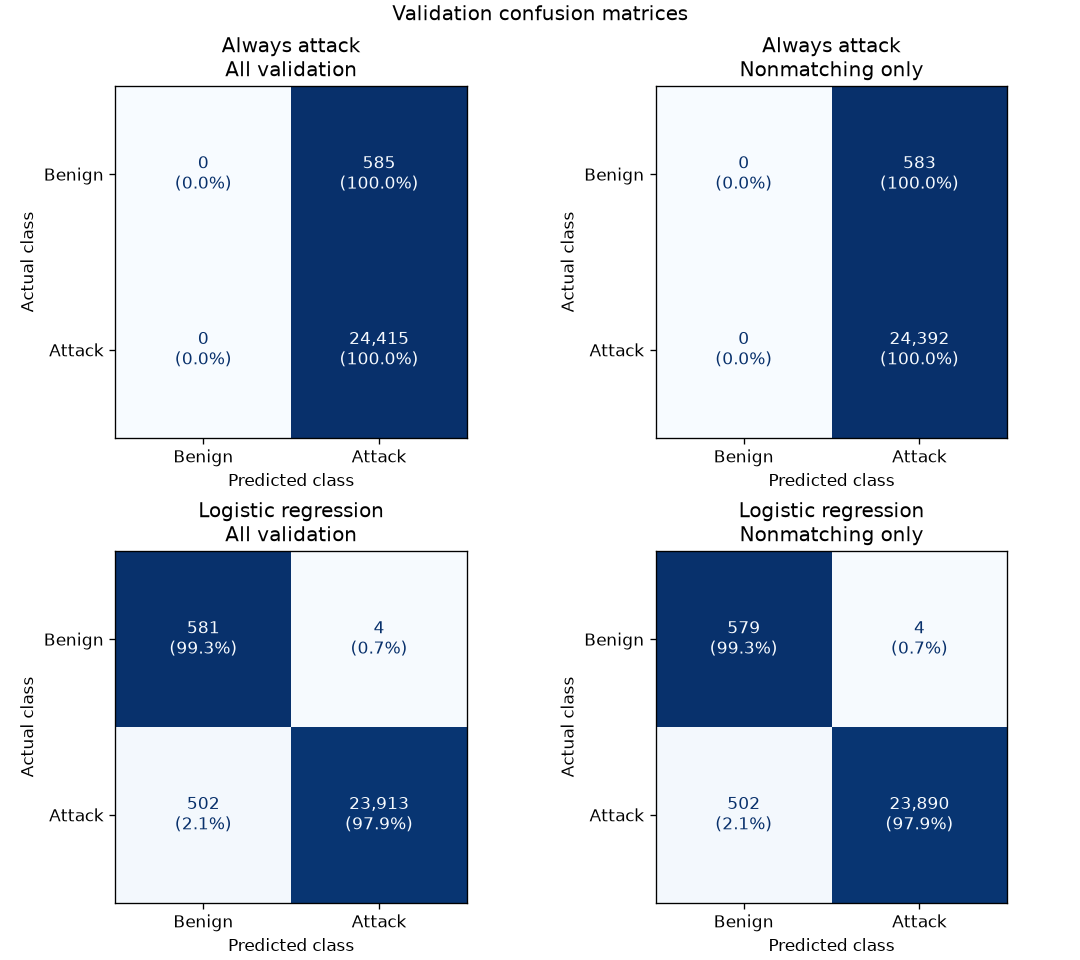

In [5]:
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

y_validation = targets["Validation"].to_numpy()
evaluation_masks = {
    "All validation": np.ones(len(y_validation), dtype=bool),
    "Nonmatching only": ~validation_matches,
}
results = []
for name, predicted in predictions.items():
    for scope, mask in evaluation_masks.items():
        actual, selected = y_validation[mask], predicted[mask]
        tn, fp, fn, tp = confusion_matrix(actual, selected, labels=[0, 1]).ravel()
        precision, recall, f1, _ = precision_recall_fscore_support(
            actual, selected, labels=[0, 1], zero_division=0,
        )
        results.append({
            "Model": name, "Validation": scope, "Rows": len(actual),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Benign precision": precision[0], "Benign recall": recall[0], "Benign F1": f1[0],
            "Attack precision": precision[1], "Attack recall": recall[1], "Attack F1": f1[1],
            "Balanced accuracy": balanced_accuracy_score(actual, selected),
            "Benign false positives": fp,
            "Actual benign": tn + fp,
            "Benign false-positive rate": fp / (tn + fp),
        })

scores = pd.DataFrame(results).set_index(["Model", "Validation"])
formatters = {
    column: "{:.4%}" for column in scores.columns if pd.api.types.is_float_dtype(scores[column])
}
formatted = scores.copy()
for column, formatter in formatters.items():
    formatted[column] = formatted[column].map(formatter.format)
with pd.option_context("display.max_columns", None, "display.width", 240):
    display(formatted)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
fig.suptitle("Validation confusion matrices")
for (model, scope), ax in zip(scores.index, axes.flat, strict=True):
    counts = scores.loc[(model, scope), ["TN", "FP", "FN", "TP"]].to_numpy(dtype=int).reshape(2, 2)
    rates = counts / counts.sum(axis=1, keepdims=True)
    matrix = ConfusionMatrixDisplay(rates, display_labels=["Benign", "Attack"])
    matrix.plot(ax=ax, cmap="Blues", colorbar=False, values_format=".1%", im_kw={"vmin": 0, "vmax": 1})
    for label, count, rate in zip(matrix.text_.flat, counts.flat, rates.flat, strict=True):
        label.set_text(f"{count:,}\n({rate:.1%})")
    ax.set_title(f"{model}\n{scope}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.show()

**Interpretation.** On full validation, the always-attack rule flagged every benign row. Logistic regression flagged 4 of 585 benign rows (0.68%) and reached 98.63% balanced accuracy versus 50.00% for the reference.

## Measure the effect of excluding overlaps

Subtract each full-validation result from its nonmatching-only counterpart. Report classification metric changes in percentage points and confusion matrix changes in rows.

In [6]:
all_scores = scores.xs("All validation", level="Validation")
nonmatching_scores = scores.xs("Nonmatching only", level="Validation")
delta_columns = ["TN", "FP", "FN", "TP", *formatters]
changes = nonmatching_scores[delta_columns] - all_scores[delta_columns]
changes[list(formatters)] *= 100
delta_formatters = {column: "{:+.4f} pp" for column in formatters}
delta_formatters.update({column: "{:+d}" for column in ["TN", "FP", "FN", "TP"]})
formatted = changes.copy()
for column, formatter in delta_formatters.items():
    formatted[column] = formatted[column].map(formatter.format)
with pd.option_context("display.max_columns", None, "display.width", 240):
    display(formatted)

,TN,FP,FN,TP,Benign precision,Benign recall,Benign F1,Attack precision,Attack recall,Attack F1,Balanced accuracy,Benign false-positive rate
Model,,,,,,,,,,,,
Always attack,+0,-2,+0,-23,+0.0000 pp,+0.0000 pp,+0.0000 pp,+0.0057 pp,+0.0000 pp,+0.0029 pp,+0.0000 pp,+0.0000 pp
Logistic regression,-2,+0,+0,-23,-0.0858 pp,-0.0023 pp,-0.0729 pp,-0.0000 pp,-0.0019 pp,-0.0010 pp,-0.0021 pp,+0.0023 pp


**Interpretation.** Excluding the 25 matches changed logistic regression balanced accuracy by -0.0021 percentage points and its benign false-positive rate by +0.0023 percentage points. The always-attack reference still flagged every benign row. The largest absolute change across the reported rates was 0.0858 percentage points.